# 02 — Modelo: split, vetorização e ajuste de hiperparâmetros

Slides **d** (conceitos), **f** (treino e teste) e **g** (estimação do modelo).

**Modelo** — recomendação baseada em conteúdo + escore de produto:

$$\text{score}(u,i) = \alpha \cdot \cos(\mathbf{p}_u, \mathbf{v}_i) + (1-\alpha) \cdot E_i$$

- $\mathbf{v}_i$: vetor de atributos do vinho — blocos multi-hot ponderados por IDF de **uvas**, **harmonização**, **estilo** (tipo, elaboração, corpo, acidez) e **origem** (país, região, vinícola), mais **numéricos** (teor alcoólico, nº de uvas, nº de safras);
- $\mathbf{p}_u = \sum_i w_{ui} \mathbf{v}_i$: perfil do usuário, soma dos vinhos que avaliou ponderada pela nota ($w_{ui} = r_{ui}$, ou $r_{ui} - b_u$ na versão centralizada, em que notas abaixo da média do usuário pesam contra);
- $E_i = (1-\beta) \cdot \widetilde{WR}_i + \beta \cdot \text{Pop}_i$: escore de produto, combinando a média bayesiana $WR_i = \frac{n_i R_i + m C}{n_i + m}$ e a popularidade $\text{Pop}_i = \log(1+n_i)/\log(1+n_{max})$.

Para **vinho novo → usuários**: $\text{aff}(u,i) = \gamma \cdot \cos(\mathbf{p}_u, \mathbf{v}_i) + (1-\gamma) \cdot \text{Ativ}_u$.

No **onboarding** (usuário novo que declara tipo, uvas e pratos), usa-se $\alpha_{onb}$ no lugar de $\alpha$, para que as escolhas explícitas não sejam abafadas pela popularidade.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import PROCESSED_DIR, load_processed

FIGS = ROOT / "slides" / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")
from src.features import WineFeaturizer
from src.model import ContentRecommender, pretty_feature
from src.split import RELEVANT_RATING, make_splits, split_summary
from src.tune import METRIC, WEIGHT_PRESETS, tune_gamma, tune_warm, validation_splits

data = load_processed()
items, ratings = data["items"], data["ratings"]

## 1. Treino e teste

| Cenário | Como é simulado |
|---|---|
| **Usuário antigo** | para cada usuário, as 20% notas **mais recentes** vão para o teste (split temporal) |
| **Usuário novo** | 10% dos usuários (com ≥ 15 notas) saem inteiros do treino; o modelo recebe só as *n* primeiras notas e é avaliado a partir da 11ª |
| **Vinho novo** | os 5% vinhos que **entraram por último** no catálogo (data da 1ª avaliação) têm todas as notas removidas do treino |

**Relevante** = nota ≥ 4,5 (22% das notas; 4,0 é a nota típica, a moda da base).
Os hiperparâmetros são escolhidos numa **validação** que repete o mesmo procedimento só dentro do treino, para o teste ficar intocado.

In [2]:
splits = make_splits(ratings, items)
val = validation_splits(splits["train"], items)
print("Teste:"); display(split_summary(splits))
print("Validação (dentro do treino):"); display(split_summary(val))
first = ratings.groupby("item_id")["date"].min().loc[splits["cold_item_ids"]]
print(f"Vinhos novos: {len(first)}, primeira avaliação entre {first.min():%Y-%m} e {first.max():%Y-%m}")

Teste:


,conjunto,notas,usuários,vinhos,% relevantes
0,train,104795,9227,878,21.7
1,test,21625,9227,820,27.7
2,cold_users,21765,1025,848,20.4
3,cold_items_test,990,859,46,10.7


Validação (dentro do treino):


,conjunto,notas,usuários,vinhos,% relevantes
0,train,72174,8304,833,21.7
1,test,13342,8303,755,25.6
2,cold_users,18404,923,799,18.8
3,cold_items_test,754,710,44,20.6


Vinhos novos: 46, primeira avaliação entre 2018-09 e 2020-08


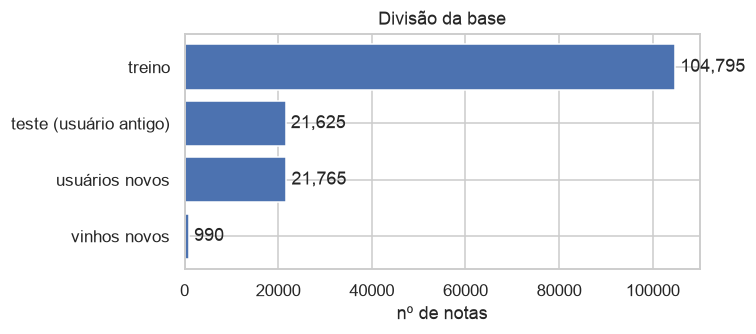

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
summ = split_summary(splits).set_index("conjunto")
labels = {"train": "treino", "test": "teste (usuário antigo)", "cold_users": "usuários novos", "cold_items_test": "vinhos novos"}
ax.barh([labels[i] for i in summ.index][::-1], summ["notas"][::-1])
for y, v in enumerate(summ["notas"][::-1]):
    ax.text(v, y, f" {v:,.0f}", va="center")
ax.set(xlabel="nº de notas", title="Divisão da base")
save(fig, "split")

## 2. Vetorização dos vinhos

In [4]:
featurizer = WineFeaturizer().fit(items)
print("Dimensões por bloco:", {b: len(v.vocabulary_) for b, v in featurizer.vecs.items()}, "| numéricos: 3")
ex = items[items["grapes"].map(lambda g: g == ["Malbec"])].head(1)
x = featurizer.transform(ex).tocoo()
top = np.argsort(-x.data)[:12]
print(ex[["name", "type", "country", "region", "winery"]].iloc[0].to_dict())
pd.Series(x.data[top], index=[pretty_feature(n) for n in featurizer.feature_names[x.col[top]]]).round(3)

Dimensões por bloco: {'grape': 111, 'harm': 40, 'style': 25, 'origin': 323} | numéricos: 3
{'name': 'Malbec Brut Rosé', 'type': 'Sparkling', 'country': 'Brazil', 'region': 'Serra Gaúcha', 'winery': 'Don Guerino'}


uva Malbec                  0.552
tipo Sparkling              0.422
combina com Rich Fish       0.356
combina com Shellfish       0.300
combina com Pork            0.296
corpo Medium-bodied         0.264
região Serra Gaúcha         0.204
país Brazil                 0.186
elaboração Varietal/100%    0.171
acidez High                 0.168
num n_vintages              0.006
num n_grapes               -0.055
dtype: float64

Atributos raros (uma vinícola, uma região) recebem IDF alto; atributos comuns (`tipo Red`, `acidez High`) pesam pouco.

## 3. Ajuste na validação: pesos dos blocos, centralização, α e β

In [5]:
cache = PROCESSED_DIR / "tuning_warm.csv"
if cache.exists():
    tuning = pd.read_csv(cache)
else:
    tuning = tune_warm(featurizer, items, val)
    tuning.to_csv(cache, index=False)
tuning.head(10).round(4)

,pesos,centralizado,m,alpha,beta,ndcg@10,precision@10,recall@10,map@10,hit@10
0,só origem,False,10,0.3,0.5,0.1804,0.0363,0.3166,0.1335,0.3462
1,só origem,False,10,0.2,0.8,0.1738,0.0364,0.3193,0.1238,0.3517
2,origem forte,False,10,0.3,0.5,0.1690,0.0353,0.3082,0.1217,0.3366
3,só origem,False,10,0.2,0.5,0.1673,0.0339,0.2949,0.1232,0.3240
4,origem forte,False,10,0.3,0.8,0.1673,0.0354,0.3118,0.1183,0.3432
5,origem forte,False,10,0.2,0.8,0.1645,0.0357,0.3125,0.1147,0.3445
6,origem forte,False,10,0.5,0.5,0.1626,0.0331,0.2886,0.1188,0.3195
7,só origem,False,10,0.3,0.8,0.1621,0.0334,0.2958,0.1163,0.3247
8,só origem,False,10,0.1,0.8,0.1594,0.0335,0.2925,0.1142,0.3229
9,só origem,True,10,0.2,0.8,0.1562,0.0324,0.2846,0.1126,0.3137


Melhor configuração absoluta: {'pesos': 'só origem', 'centralizado': False, 'alpha': 0.3, 'beta': 0.5, 'ndcg@10': 0.18035957185721174}
Só escore de produto (α = 0): 0.122 | só conteúdo (α = 1): 0.0564


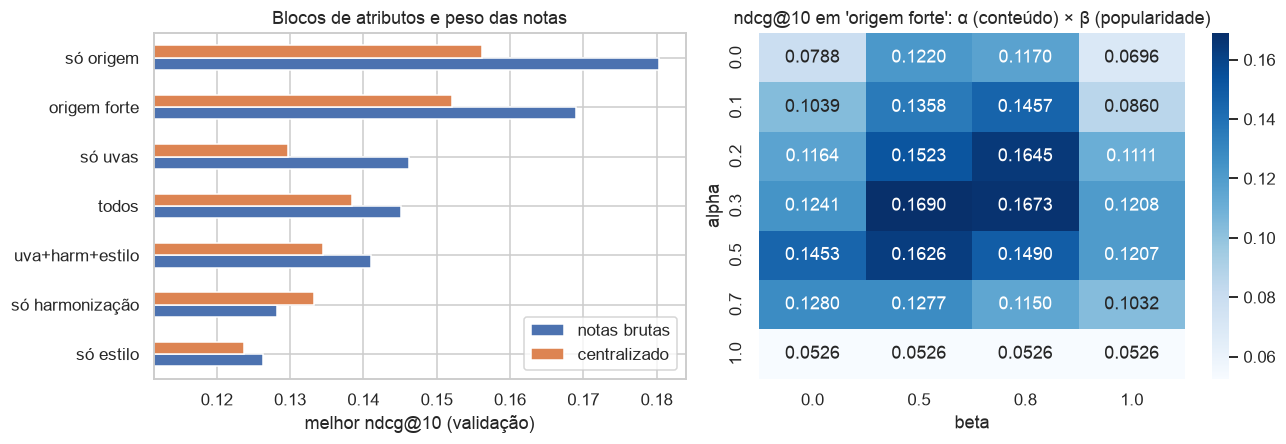

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
best_preset = tuning.groupby(["pesos", "centralizado"])[METRIC].max().unstack()
best_preset.columns = ["notas brutas" if not c else "centralizado" for c in best_preset.columns]
best_preset.sort_values(best_preset.columns[0]).plot.barh(ax=axes[0])
axes[0].set(xlabel=f"melhor {METRIC} (validação)", ylabel="", title="Blocos de atributos e peso das notas")
axes[0].set_xlim(best_preset.min().min() * 0.9, best_preset.max().max() * 1.02)

# Configuração escolhida (ver célula seguinte): a melhor que usa os blocos do onboarding.
b = tuning[tuning["pesos"].map(lambda p: all(WEIGHT_PRESETS[p][k] > 0 for k in ["grape", "harm", "style"]))].iloc[0]
grid = tuning[(tuning["pesos"] == b["pesos"]) & (tuning["centralizado"] == b["centralizado"])]
sns.heatmap(grid.pivot_table(index="alpha", columns="beta", values=METRIC), annot=True, fmt=".4f",
            cmap="Blues", ax=axes[1])
axes[1].set(title=f"{METRIC} em '{b['pesos']}': α (conteúdo) × β (popularidade)")
save(fig, "tuning_warm")
print("Melhor configuração absoluta:", tuning.iloc[0][["pesos", "centralizado", "alpha", "beta", METRIC]].to_dict())
print("Só escore de produto (α = 0):", round(tuning.loc[tuning["alpha"] == 0, METRIC].max(), 4),
      "| só conteúdo (α = 1):", round(tuning.loc[tuning["alpha"] == 1, METRIC].max(), 4))

**Escolha da configuração.** A melhor absoluta pode zerar blocos que o **usuário novo** escolhe no onboarding (uvas, harmonização, estilo); com peso zero, essas escolhas não teriam efeito. Por isso fica a melhor configuração entre as que usam esses três blocos, e o custo em relação à melhor absoluta é registrado.

In [7]:
usable = tuning[tuning["pesos"].map(lambda p: all(WEIGHT_PRESETS[p][k] > 0 for k in ["grape", "harm", "style"]))]
best = usable.iloc[0]
print("Escolhida:", best[["pesos", "centralizado", "alpha", "beta", METRIC]].to_dict())
print(f"Melhor absoluta: {tuning.iloc[0]['pesos']} ({tuning[METRIC].max():.4f}) → custo de "
      f"{best[METRIC] / tuning[METRIC].max() - 1:+.1%} para o onboarding funcionar")


Escolhida: {'pesos': 'origem forte', 'centralizado': False, 'alpha': 0.3, 'beta': 0.5, 'ndcg@10': 0.16895855940923676}
Melhor absoluta: só origem (0.1804) → custo de -6.3% para o onboarding funcionar


,gamma,auc,ndcg@10,recall@10,hit@10
0,0.00,0.3887,0.0000,0.0000,0.0000
1,0.10,0.4136,0.0000,0.0000,0.0000
2,0.25,0.4543,0.0000,0.0000,0.0000
3,0.50,0.5225,0.0000,0.0000,0.0000
4,0.75,0.5840,0.0247,0.0175,0.0526
5,0.90,0.6184,0.0143,0.0180,0.1053
6,1.00,0.6356,0.0113,0.0180,0.1053


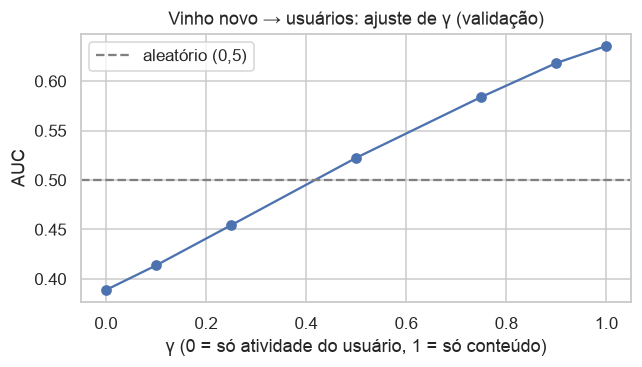

In [8]:

W = WEIGHT_PRESETS[best["pesos"]]
featurizer = WineFeaturizer(weights=W).fit(items)
vwarm = items[items["item_id"].isin(val["warm_item_ids"])]
model_val = ContentRecommender(featurizer, alpha=best["alpha"], beta=best["beta"],
                               centered=bool(best["centralizado"]), m=int(best["m"])).fit(val["train"], vwarm)
gamma_res = tune_gamma(model_val, items, val)
best_gamma = float(gamma_res.loc[gamma_res["auc"].idxmax(), "gamma"])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(gamma_res["gamma"], gamma_res["auc"], marker="o")
ax.axhline(0.5, ls="--", c="gray", label="aleatório (0,5)")
ax.set(xlabel="γ (0 = só atividade do usuário, 1 = só conteúdo)", ylabel="AUC",
       title="Vinho novo → usuários: ajuste de γ (validação)")
ax.legend()
save(fig, "tuning_gamma")
gamma_res.round(4)

In [9]:
# α_onboarding: preferências declaradas no onboarding não têm como ser validadas na base
# (ninguém "declarou" nada); com o α validado (perfis de notas), quem pede Malbec recebe
# quase só campeões de popularidade. 0,6 é decisão de projeto, documentada no slide.
params = {"weights": W, "alpha": float(best["alpha"]), "beta": float(best["beta"]),
          "gamma": best_gamma, "centered": bool(best["centralizado"]), "m": int(best["m"]),
          "alpha_onboarding": 0.6}
(PROCESSED_DIR / "best_params.json").write_text(json.dumps(params, indent=2, ensure_ascii=False))
params

{'weights': {'grape': 1.0,
  'harm': 0.5,
  'style': 1.0,
  'origin': 1.5,
  'num': 0.3},
 'alpha': 0.3,
 'beta': 0.5,
 'gamma': 1.0,
 'centered': False,
 'm': 10,
 'alpha_onboarding': 0.6}